In [1]:
from pathlib import Path 
import os 

from dotenv import dotenv_values
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.stats import linregress
import numpy as np
import pandas as pd 

In [ ]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Fig_01"
os.makedirs(OUTDIR, exist_ok=True)

COORD_FP = DATADIR / "11_brainrender" / "coord_space_ext.csv" # from 11_brainrender/1_precompute..

In [ ]:
coords = pd.read_csv(COORD_FP)

In [6]:
coords.head(3)

,x_ccf,y_ccf,z_ccf,allen_id,allen_acronym,is_inside_HY,ST_cell_counts,is_HY_structure,estimated_sc_cell_counts
0,4375.0,3950.000048,3049.999952,672,CP,False,0,False,0.113910
1,4375.0,3950.000048,3075.000048,672,CP,False,0,False,0.120328
2,4375.0,3950.000048,3100.000143,672,CP,False,1,False,0.126162


In [7]:
def get_cells_per_vox(coords, column_name):
    num_vox_per_nuc = coords.groupby("allen_acronym")[column_name].count()
    num_vox_per_nuc.name = "num_vox_per_nuc"
    num_cells_per_nuc = coords.groupby("allen_acronym")[column_name].sum()
    num_cells_per_nuc.name = "num_cells_per_nuc"
    scatter_df = pd.concat([num_vox_per_nuc, num_cells_per_nuc],axis=1).reset_index()
    scatter_df.allen_acronym = scatter_df.allen_acronym.astype(str)
    scatter_df["structure_descends_from_HY"] = scatter_df.allen_acronym.map(coords.set_index("allen_acronym")["is_HY_structure"].to_dict())
    scatter_df["cells_per_vox"] = scatter_df.num_cells_per_nuc / scatter_df.num_vox_per_nuc
    return scatter_df

In [ ]:
# import matplotlib as mpl
# print(mpl.rcParams["pdf.fonttype"])

plt.rcParams["pdf.fonttype"] = 42

3


## ST figure

In [10]:
st_cells = get_cells_per_vox(coords, "ST_cell_counts")
st_cells[st_cells.structure_descends_from_HY].sort_values(by="cells_per_vox", ascending=False).head(3)

,allen_acronym,num_vox_per_nuc,num_cells_per_nuc,structure_descends_from_HY,cells_per_vox
134,SCH,2112,3274,True,1.550189
118,PVH,5987,7960,True,1.329547
121,PVa,1611,2111,True,1.310366


/tmp/ipykernel_106073/1915286164.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[3.50852972 4.35602586 3.96722026 2.29003461 3.46819959 3.77290819
 4.07598468 3.88879707 4.94943392 4.82156593 3.39550112 4.249076
 3.44122367 3.22993769 3.41195624 3.83384805 3.63988474 3.44420099
 3.1202448  4.10967977 4.25154089 2.58771097 2.56702637 4.36104754
 3.62479758 3.79699039 3.49009901 2.61595005 3.72623805 3.77720926
 3.623766   3.20709554 3.79546289 3.61940641 3.71323846 3.83575397
 3.67559506 3.5390761  3.32469391 3.17260293 3.79406958 3.924796
 3.04493155 3.54007909 4.22411851 3.33041377 4.24442557 3.20601588
 4.69799609]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  subset.loc[:, "num_vox_per_nuc"] = np.log10(subset.loc[:, "num_vox_per_nuc"])
/tmp/ipykernel_106073/1915286164.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a futu

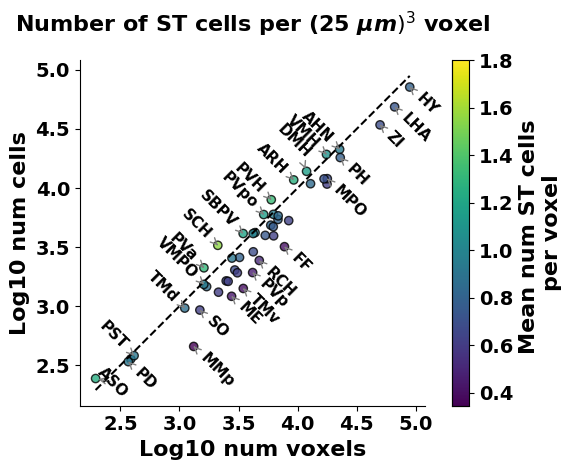

In [11]:
VMAX = 1.8 

# Subset
subset = st_cells[(st_cells["structure_descends_from_HY"]) 
]

subset.loc[:, "num_vox_per_nuc"] = np.log10(subset.loc[:, "num_vox_per_nuc"])
subset.loc[:, "num_cells_per_nuc"] = np.log10(subset.loc[:, "num_cells_per_nuc"])

# Extract x and y
x = subset["num_vox_per_nuc"]
y = subset["num_cells_per_nuc"]

# Fit regression line
slope, intercept, *_ = linregress(x, y)

# Normalize color values for colorbar
norm = mcolors.Normalize(vmin=subset["cells_per_vox"].min(), vmax=VMAX, # hardcoded to 1.5 as this is the max in the brainglobe plots 
    #vmax=subset["cells_per_vox"].max()
)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
sm.set_array([])

# Plot setup
fig, ax = plt.subplots()

# Scatter plot
points = ax.scatter(
    x,
    y,
    c=subset["cells_per_vox"],
    cmap="viridis",
    edgecolor="k",
    alpha=0.8,
    vmax=VMAX

)

# Parameters
epsilon = 0.15 #1000
offset = 0.075 #2000 # data units

nuc_manual_format_dict = {
    "HY": {
        "offset_x": offset,
        "offset_y": -offset,
        "rotation": -45,
        "ha": "left"
    }, 
    "LHA": {
        "offset_x": offset,
        "offset_y": -offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "PH": {
        "offset_x": offset,
        "offset_y": -offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "ASO": {
        "offset_x": 0.5*offset,
        "offset_y": offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "PD": {
        "offset_x": offset,
        "offset_y": -offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "DMH": {
        "offset_x": -3*offset,
        "offset_y": 5*offset,
        "rotation": -45,
        "ha": "left"
    }, 

}

do_not_annotate_list = [#"TMd", 
#"TMv", 
    "LM", "MMd",
      "AVP", "PS",
     "LPO",  "OV", "MMme", "VLPO", "MEPO", "TU", "LPO",
    # "ME",
]


# Annotate
for idx, row in subset.iterrows():
    x_i = row["num_vox_per_nuc"]
    y_i = row["num_cells_per_nuc"]
    nuc = row["allen_acronym"]
    y_hat = slope * x_i + intercept
    dist = y_i - y_hat

    if nuc in do_not_annotate_list:
        continue

    if (abs(dist) > epsilon) | (x_i > 4.2) | (x_i < 3.5):
        #print(nuc)
        if nuc in nuc_manual_format_dict.keys():
            offset_x = nuc_manual_format_dict[nuc]["offset_x"]
            offset_y = nuc_manual_format_dict[nuc]["offset_y"]
            rotation = nuc_manual_format_dict[nuc]["rotation"]
            ha = nuc_manual_format_dict[nuc]["ha"]
        elif dist > 0:
            # Above regression: point to top-left
            offset_x = -offset
            offset_y = offset
            rotation = -45
            ha = 'right'
        else:
            # Below regression: point to bottom-right
            offset_x = offset
            offset_y = -offset
            rotation = -45
            ha = 'left'

        ax.annotate(
            row["allen_acronym"],
            xy=(x_i, y_i),
            xytext=(x_i + offset_x, y_i + offset_y),
            textcoords='data',
            arrowprops=dict(arrowstyle='->', color='gray', lw=1),
            fontsize=11,
            fontweight="bold",
            ha=ha,
            va='center',
            rotation=rotation,
            rotation_mode='anchor'  # ensures rotation respects alignment
        )

# Colorbar
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Mean num ST cells \nper voxel", fontsize=16, fontweight="bold")

for label in ax.get_xticklabels() + ax.get_yticklabels() + cbar.ax.get_yticklabels():
    label.set_fontsize(14)
    label.set_fontweight("bold")


# Add black diagonal line
min_val = min(subset["num_vox_per_nuc"].min(), subset["num_cells_per_nuc"].min())
max_val = max(subset["num_vox_per_nuc"].max(), subset["num_cells_per_nuc"].max())
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--')

# Labels and title
ax.set_xlabel("Log10 num voxels", fontsize=16, fontweight="bold")
ax.set_ylabel("Log10 num cells", fontsize=16, fontweight="bold")
ax.set_title(
    r"Number of ST cells per $\boldsymbol{(25\ \mu m)^{3}}$ voxel",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_aspect("equal")
plt.tight_layout()
sns.despine()

fig.savefig(OUTDIR / "st_cells_per_vox_and_nuc_scatter.pdf", dpi=300)

plt.show()


## SC figure

In [12]:
sc_cells = get_cells_per_vox(coords, "estimated_sc_cell_counts")
sc_cells[sc_cells.structure_descends_from_HY].sort_values(by="cells_per_vox", ascending=False).head(5)

,allen_acronym,num_vox_per_nuc,num_cells_per_nuc,structure_descends_from_HY,cells_per_vox
134,SCH,2112,11970.205221,True,5.667711
8,ARH,9273,38955.090940,True,4.200916
133,SBPV,3460,14094.238968,True,4.073479
121,PVa,1611,6242.304309,True,3.874801
34,DMH,11912,44096.836521,True,3.701884


/tmp/ipykernel_106073/316348643.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[3.50852972 4.35602586 3.96722026 2.29003461 3.46819959 3.77290819
 4.07598468 3.88879707 4.94943392 4.82156593 3.39550112 4.249076
 3.44122367 3.22993769 3.41195624 3.83384805 3.63988474 3.44420099
 3.1202448  4.10967977 4.25154089 2.58771097 2.56702637 4.36104754
 3.62479758 3.79699039 3.49009901 2.61595005 3.72623805 3.77720926
 3.623766   3.20709554 3.79546289 3.61940641 3.71323846 3.83575397
 3.67559506 3.5390761  3.32469391 3.17260293 3.79406958 3.924796
 3.04493155 3.54007909 4.22411851 3.33041377 4.24442557 3.20601588
 4.69799609]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  subset.loc[:, "num_vox_per_nuc"] = np.log10(subset.loc[:, "num_vox_per_nuc"])


2.290034611362518 5.163081646057782


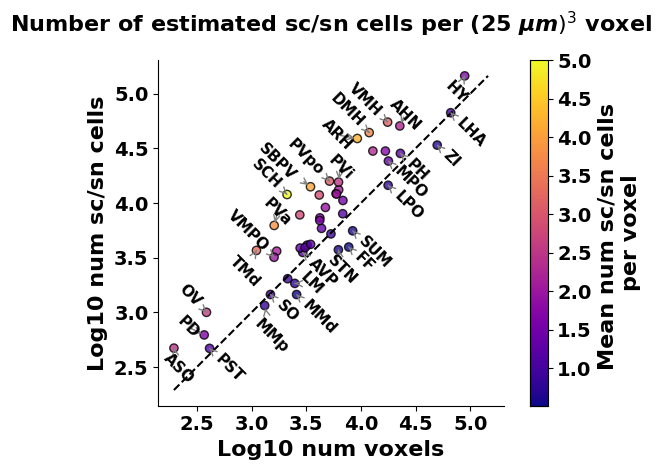

In [13]:

VMAX = 5 # SCH is exceeding this with 5.67

# Subset
subset = sc_cells.loc[sc_cells.structure_descends_from_HY,:].reset_index().copy()

subset.loc[:, "num_vox_per_nuc"] = np.log10(subset.loc[:, "num_vox_per_nuc"])
subset.loc[:, "num_cells_per_nuc"] = np.log10(subset.loc[:, "num_cells_per_nuc"])

# Extract x and y
x = subset["num_vox_per_nuc"]
y = subset["num_cells_per_nuc"]

# Fit regression line
slope, intercept, *_ = linregress(x, y)

# Normalize color values for colorbar
norm = mcolors.Normalize(vmin=subset["cells_per_vox"].min(), vmax=VMAX,
)
sm = plt.cm.ScalarMappable(cmap="plasma", norm=norm)
sm.set_array([])

# Plot setup
fig, ax = plt.subplots()

# Scatter plot
points = ax.scatter(
    x,
    y,
    c=subset["cells_per_vox"],
    cmap="plasma",
    edgecolor="k",
    alpha=0.8,
    vmax=VMAX

)

# Parameters
epsilon = 0.15 #1000
offset = 0.075 #2000 # data units

nuc_manual_format_dict = {

    "LHA": {
        "offset_x": offset,
        "offset_y": -offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "PH": {
        "offset_x": offset,
        "offset_y": -offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "ASO": {
        "offset_x": -1*offset,
        "offset_y": -1*offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "PD": {
        "offset_x": -3*offset,
        "offset_y": 2*offset,
        "rotation": -45,
        "ha": "left"
    }, 


    "SBPV": {
        "offset_x": -6*offset,
        "offset_y": 5*offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "HY": {
        "offset_x": -2*offset,
        "offset_y": -1*offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "STN": {
        "offset_x": -1*offset,
        "offset_y": -1*offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "TMd": {
        "offset_x": -3*offset,
        "offset_y": -1*offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "LM": {
        "offset_x": 1*offset,
        "offset_y": 1*offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "MMp": {
        "offset_x": -1*offset,
        "offset_y": -2*offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "AHN": {
        "offset_x": -1*offset,
        "offset_y": 3*offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "ARH": {
        "offset_x": -4*offset,
        "offset_y": 2*offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "PVH": {
        "offset_x": -1*offset,
        "offset_y": 1*offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "PVi": {
        "offset_x": -1*offset,
        "offset_y": 3*offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "PVa": {
        "offset_x": -1*offset,
        "offset_y": 3*offset,
        "rotation": -45,
        "ha": "left"
    }, 

    "FF": {
        "offset_x": 1*offset,
        "offset_y": -1*offset,
        "rotation": -45,
        "ha": "left"
    }, 
}

do_not_annotate_list = [
    "ME",
     "VLPO",
    "TU",
    "PS",
    "MPN",
     "MEPO",
     "PSTN", 
     "MMme",
     "PVp"
]


# Annotate
for idx, row in subset.iterrows():
    x_i = row["num_vox_per_nuc"]
    y_i = row["num_cells_per_nuc"]
    nuc = row["allen_acronym"]
    y_hat = slope * x_i + intercept
    dist = y_i - y_hat

    if nuc in do_not_annotate_list:
        continue

    if (abs(dist) > epsilon) | (x_i > 4.2) | (x_i < 3.5):
        #print(nuc)
        if nuc in nuc_manual_format_dict.keys():
            offset_x = nuc_manual_format_dict[nuc]["offset_x"]
            offset_y = nuc_manual_format_dict[nuc]["offset_y"]
            rotation = nuc_manual_format_dict[nuc]["rotation"]
            ha = nuc_manual_format_dict[nuc]["ha"]
        elif dist > 0:
            # Above regression: point to top-left
            offset_x = -offset
            offset_y = offset
            rotation = -45
            ha = 'right'
        else:
            # Below regression: point to bottom-right
            offset_x = offset
            offset_y = -offset
            rotation = -45
            ha = 'left'

        ax.annotate(
            row["allen_acronym"],
            xy=(x_i, y_i),
            xytext=(x_i + offset_x, y_i + offset_y),
            textcoords='data',
            arrowprops=dict(arrowstyle='->', color='gray', lw=1),
            fontsize=11,
            fontweight="bold",
            ha=ha,
            va='center',
            rotation=rotation,
            rotation_mode='anchor'  # ensures rotation respects alignment
        )

# Colorbar
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Mean num sc/sn cells \nper voxel", fontsize=16, fontweight="bold")

for label in ax.get_xticklabels() + ax.get_yticklabels() + cbar.ax.get_yticklabels():
    label.set_fontsize(14)
    label.set_fontweight("bold")

# Add black diagonal line
min_val = min(subset["num_vox_per_nuc"].min(), subset["num_cells_per_nuc"].min())
max_val = max(subset["num_vox_per_nuc"].max(), subset["num_cells_per_nuc"].max())

print(min_val, max_val)
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--')

# Labels and title
ax.set_xlabel("Log10 num voxels", fontsize=16, fontweight="bold")
ax.set_ylabel("Log10 num sc/sn cells", fontsize=16, fontweight="bold")

ax.set_title(
    r"Number of estimated sc/sn cells per $\boldsymbol{(25\ \mu m)^{3}}$ voxel",
    fontsize=16,
    fontweight="bold",
    pad=20
)
ax.set_aspect("equal")
plt.tight_layout()
sns.despine()

fig.savefig(OUTDIR / "sc_cells_per_vox_and_nuc_scatter.pdf", dpi=300, bbox_inches="tight")

plt.show()
